# 📓 Qdislib Hello World! Serial Mode

This notebook demonstrates how to perform circuit cutting using Qdislib without requiring PyCOMPSs.
This is useful for local, serial execution of quantum circuit cutting.

### 🔧 1. Install Qdislib

If not already installed, run the following:

`!pip install Qdislib`

No other configuration needed to run in serial mode!!!

### 🧠 2. Importing Required Modules

Modules:

* qibo.models, qibo.gates, qibo.hamiltonians: for defining and manipulating quantum circuits.

* qd: likely refers to Qdislib, which contains the circuit cutting functions.

Setup:

* Sets the backend for Qibo ("numpy") to run locally on CPU.

In [51]:
import numpy as np
import qibo
from qibo import models, gates, hamiltonians, callbacks
from qibo.models import Circuit
from qibo.symbols import X, Y, Z, I
from qibo.ui import plot_circuit

qibo.__version__
qibo.set_backend("numpy")

[Qibo 0.2.16|INFO|2025-05-26 15:12:45]: Using numpy backend on /CPU:0


Import Qdislib where the circuit cutting is implemented

In [52]:
import Qdislib.api as qd

### ⚙️ 3. Define the Main Circuit

Function entire_circuit(): builds a 10-qubit circuit with:

* Single-qubit gates: H, RX, RY, RZ.

* Two-qubit gates: CZ.

Circuit Objective: Simulates a non-trivial entangled circuit useful for demonstrating cutting algorithms.

(<Axes: >, <Figure size 700x500 with 1 Axes>)

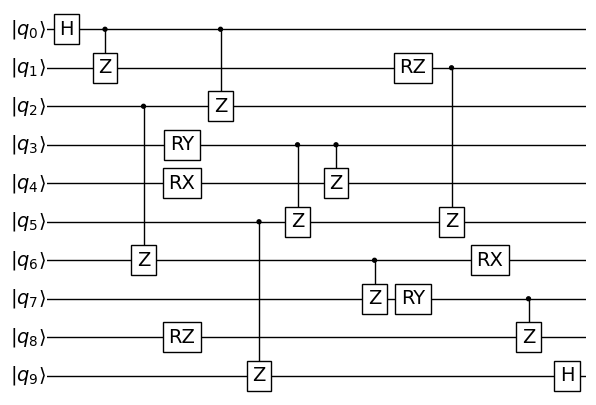

In [53]:
def entire_circuit():
    nqubits = 10
    circuit = models.Circuit(nqubits)

    circuit.add(gates.H(0))
    circuit.add(gates.CZ(0, 1))
    circuit.add(gates.CZ(2, 6))
    circuit.add(gates.RZ(8, np.pi / 3))

    circuit.add(gates.RY(3, np.pi / 5))
    circuit.add(gates.RX(4, np.pi / 5))
    circuit.add(gates.CZ(0, 2))
    circuit.add(gates.CZ(5, 9))

    circuit.add(gates.CZ(3, 5))
    circuit.add(gates.CZ(3, 4))
    circuit.add(gates.CZ(6, 7))
    circuit.add(gates.RY(7, np.pi / 5))
    circuit.add(gates.RZ(1, np.pi / 5))

    circuit.add(gates.CZ(1, 5))
    circuit.add(gates.RX(6, np.pi / 5))
    circuit.add(gates.CZ(7, 8))

    circuit.add(gates.H(9))
    return circuit


circuit = entire_circuit()
# print(circuit.draw())
plot_circuit(circuit, scale=0.5)

### ✂️ 4. Gate Cutting Example

qd.find_cut(circuit): Automatically identifies gates suitable for cutting.

* Example result: ['CZ_2']


qd.gate_cutting(circuit, cut):

* Applies the gate cutting algorithm.

* Cuts the circuit at the specified gate.

* Evaluates subcircuits and reconstructs the expectation value.

* Output: A reconstructed value (e.g., 0.0084...).

In [54]:
circuit = entire_circuit()

cut = qd.find_cut(circuit)
print(cut)

['CZ_2']


In [55]:
reconstruction = qd.gate_cutting(circuit, cut)
print(reconstruction)

0.0036468505859375


### 🔌 5. Wire Cutting Example

find_cut(..., gate_cut=False):

* Finds cuts (pairs of gates) between which a wire cut is possible.

* Force the algorithm to only finde wire cuts (setting gate_cut=False)

* Example: [('CZ_2', 'CZ_7')]

qd.wire_cutting(...):

* Applies the wire cutting method across the selected gates.

* Calculates the reconstructed expectation value.

In [56]:
circuit = entire_circuit()

cut = qd.find_cut(circuit, gate_cut=False)
print(cut)

[('CZ_2', 'CZ_7')]


In [57]:
reconstruction = qd.wire_cutting(circuit, cut)
print(reconstruction)

[Qibo 0.2.16|INFO|2025-05-26 15:12:46]: Using numpy backend on /CPU:0
[Qibo 0.2.16|INFO|2025-05-26 15:12:46]: Using numpy backend on /CPU:0
[Qibo 0.2.16|INFO|2025-05-26 15:12:46]: Using numpy backend on /CPU:0
[Qibo 0.2.16|INFO|2025-05-26 15:12:46]: Using numpy backend on /CPU:0
[Qibo 0.2.16|INFO|2025-05-26 15:12:46]: Using numpy backend on /CPU:0
[Qibo 0.2.16|INFO|2025-05-26 15:12:46]: Using numpy backend on /CPU:0
[Qibo 0.2.16|INFO|2025-05-26 15:12:46]: Using numpy backend on /CPU:0
[Qibo 0.2.16|INFO|2025-05-26 15:12:46]: Using numpy backend on /CPU:0
[Qibo 0.2.16|INFO|2025-05-26 15:12:46]: Using numpy backend on /CPU:0
[Qibo 0.2.16|INFO|2025-05-26 15:12:46]: Using numpy backend on /CPU:0
[Qibo 0.2.16|INFO|2025-05-26 15:12:46]: Using numpy backend on /CPU:0
[Qibo 0.2.16|INFO|2025-05-26 15:12:46]: Using numpy backend on /CPU:0
[Qibo 0.2.16|INFO|2025-05-26 15:12:46]: Using numpy backend on /CPU:0
[Qibo 0.2.16|INFO|2025-05-26 15:12:46]: Using numpy backend on /CPU:0
[Qibo 0.2.16|INFO|20

0.0036449599999999914


### 📊 6. Exact Expected Value

qd.analytical_solution(circuit, "Z"*nqubits):

* Computes the expected value using a symbolic statevector.

* Used as a ground-truth comparison.

* Observable can be modified

Observation: Returns exact expected value — allows evaluation of gate cutting accuracy.

In [58]:
circuit = entire_circuit()

analytic = qd.analytical_solution(circuit, "Z" * circuit.nqubits)
print(analytic)

0.0


### 🧩 7. Gate Cutting with Subcircuits

qd.gate_cutting_subcircuits(...):

* Performs gate cutting like before but also returns the subcircuits used for reconstruction.

compss_wait_on(subcircuits): Synchronizes and retrieves the results (used with PyCOMPSs).

Printed output: Visual representation of generated subcircuits using Qiskit's circuit print.

['CZ_2']


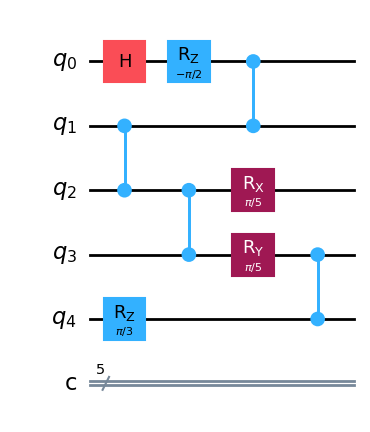

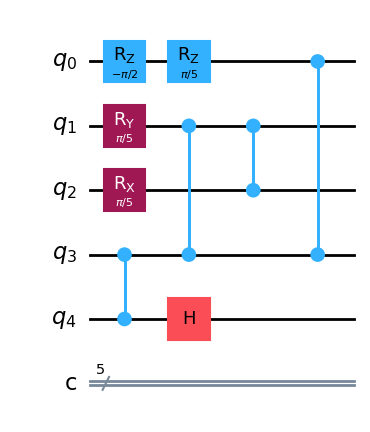

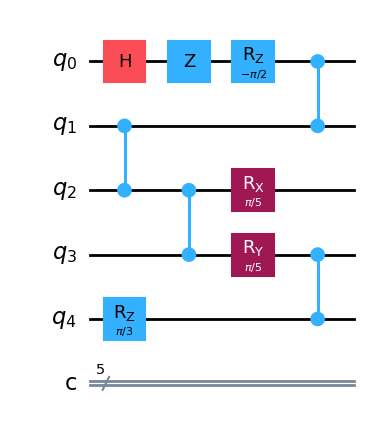

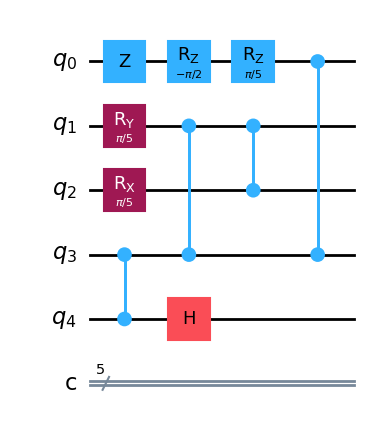

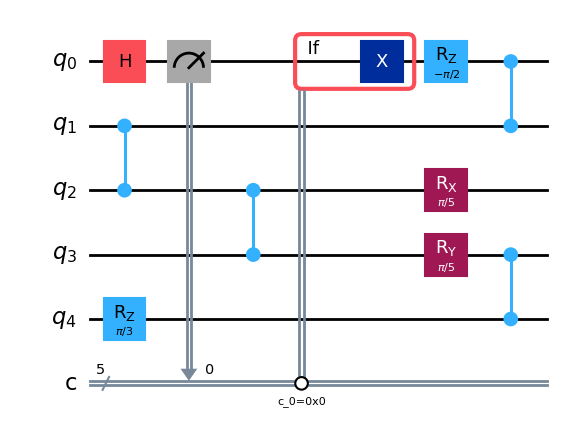

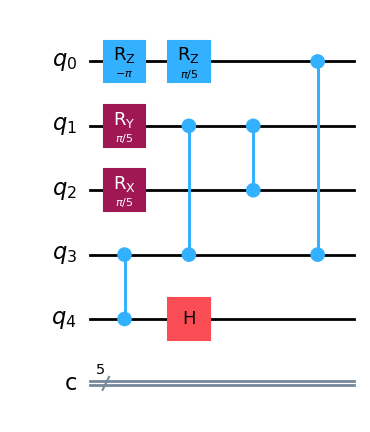

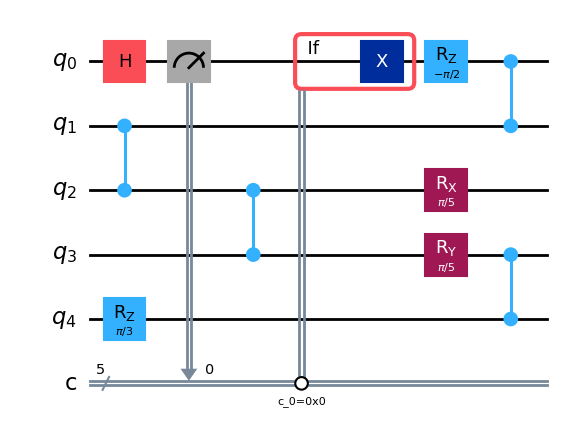

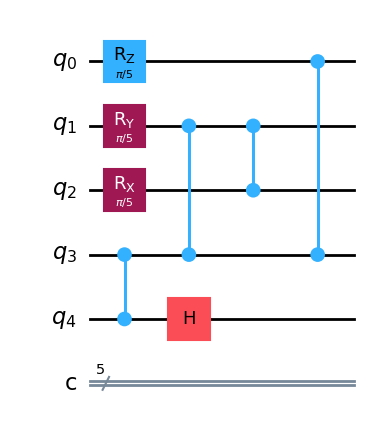

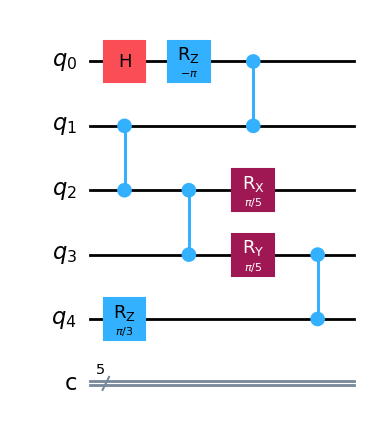

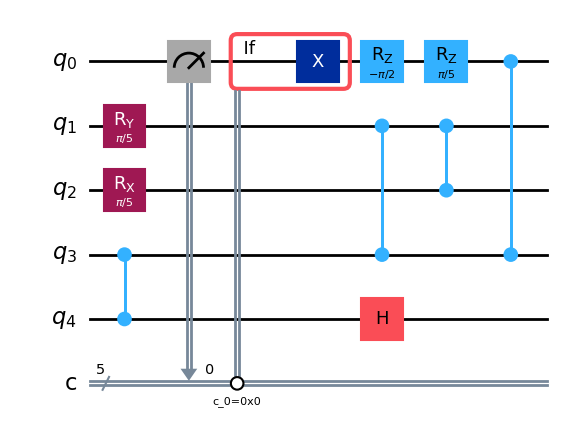

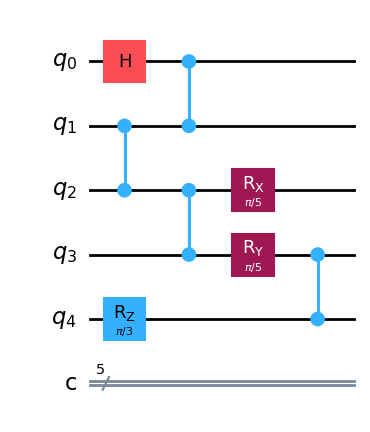

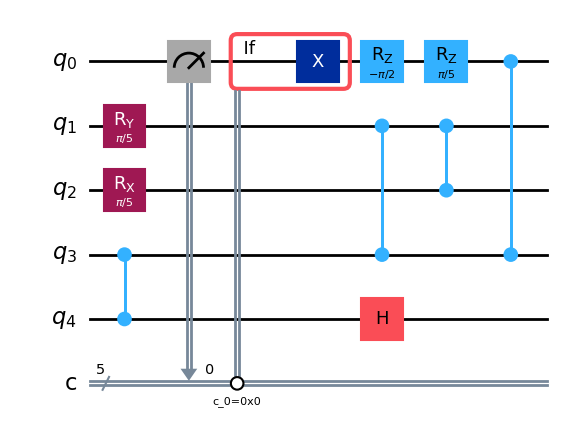

In [59]:
circuit = entire_circuit()

cut = qd.find_cut(circuit)
print(cut)
subcircuits = qd.gate_cutting_subcircuits(circuit, cut, "qiskit")

for subcirc in subcircuits:
    display(subcirc.draw(output="mpl"))

### 🧩 7.b Reconstruction Gate Cutting with Subcircuits

In this section, we demonstrate the reconstruction of the expectation value of a quantum circuit that has been partitioned into subcircuits using gate cutting. Each subcircuit is simulated independently, and their results are combined to approximate the expectation value of the original (uncut) circuit.

The process follows these main steps:

* Execute each subcircuit individually to obtain its contribution to the total expectation value.

* Use the reconstruction algorithm to combine the individual results and approximate the expectation value of the full circuit.

In [60]:
from Qdislib.core.cutting_algorithms.gate_cutting import _expec_value_qiskit

results = []
for subcircuit in subcircuits:
    # Execute individually each subcircuit
    result = _expec_value_qiskit(subcircuit)
    results.append(result)

# Array with the individual expectation values of each subcircuit
print(results)

# Reconstruction of the original circuit expected value from the array of results
recons = qd.gate_cutting_subcircuit_reconstruction(results,number_cuts=1)
print(recons)

[-0.06640625, -0.01953125, 0.00390625, 0.005859375, -0.701171875, 0.01171875, -0.619140625, 0.041015625, 0.0078125, 0.0234375, -0.009765625, 0.017578125]
0.009426116943359375


### 🧩 8. Wire Cutting with Subcircuits

Same as gate cutting, but uses wire cutting logic.

Subcircuits generated are more complex and may include measurements and resets.

Visuals: Many circuit renderings show various Qiskit circuits built from the wire cut portions.

[('CZ_2', 'CZ_7')]


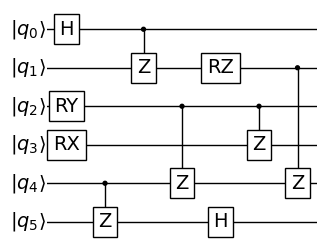

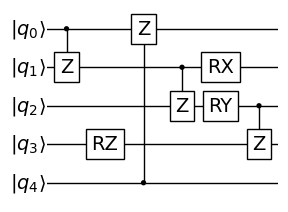

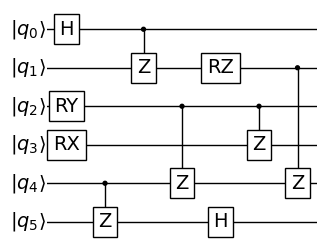

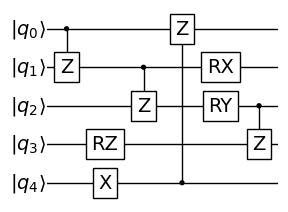

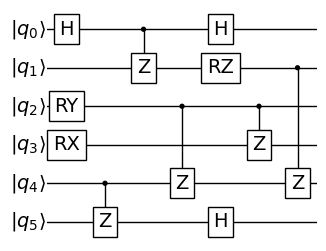

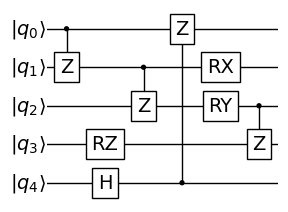

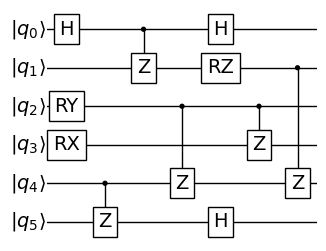

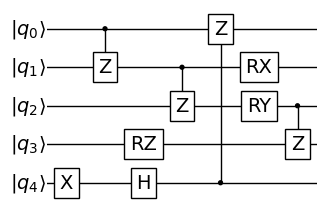

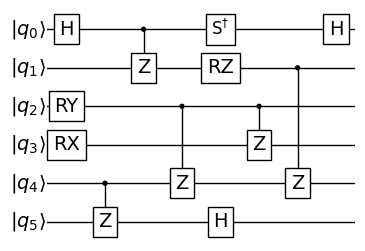

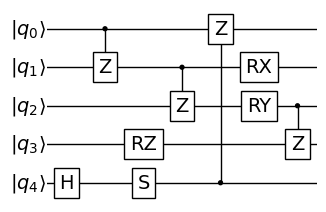

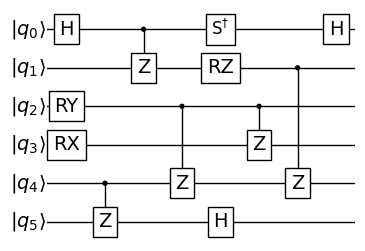

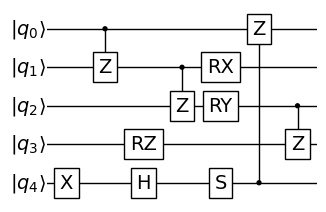

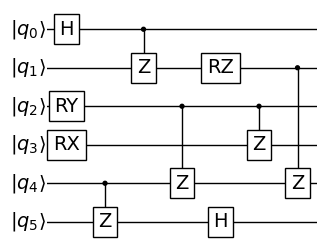

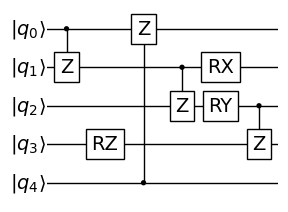

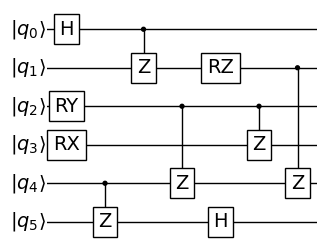

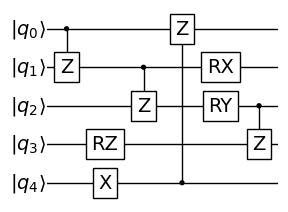

In [61]:
circuit = entire_circuit()

cut = qd.find_cut(circuit, gate_cut=False)
print(cut)
subcircuits = qd.wire_cutting_subcircuits(circuit, cut, "qibo")

for subcirc in subcircuits:
    plot_circuit(subcirc, scale=0.5)

### 🧩 8.b Reconstruction Wire Cutting with Subcircuits

In this section, we demonstrate the reconstruction of the expectation value of a quantum circuit that has been partitioned into subcircuits using wire cutting. Each subcircuit is simulated independently, and their results are combined to approximate the expectation value of the original (uncut) circuit.

The process follows these main steps:

* Execute each subcircuit individually to obtain its contribution to the total expectation value.

* Use the reconstruction algorithm to combine the individual results and approximate the expectation value of the full circuit.

In [62]:
from Qdislib.core.cutting_algorithms.wire_cutting import _expec_value_qibo

results = []
for subcircuit in subcircuits:
    # Execute individually each subcircuit
    result = _expec_value_qibo(subcircuit)
    results.append(result)

# Array with the individual expectation values of each subcircuit
print(results)

# Reconstruction of the original circuit expected value from the array of results
recons = qd.wire_cutting_subcircuit_reconstruction(results,number_cuts=1)
print(recons)

[Qibo 0.2.16|INFO|2025-05-26 15:12:56]: Using numpy backend on /CPU:0
[Qibo 0.2.16|INFO|2025-05-26 15:12:56]: Using numpy backend on /CPU:0
[Qibo 0.2.16|INFO|2025-05-26 15:12:56]: Using numpy backend on /CPU:0
[Qibo 0.2.16|INFO|2025-05-26 15:12:56]: Using numpy backend on /CPU:0
[Qibo 0.2.16|INFO|2025-05-26 15:12:56]: Using numpy backend on /CPU:0
[Qibo 0.2.16|INFO|2025-05-26 15:12:56]: Using numpy backend on /CPU:0
[Qibo 0.2.16|INFO|2025-05-26 15:12:56]: Using numpy backend on /CPU:0
[Qibo 0.2.16|INFO|2025-05-26 15:12:56]: Using numpy backend on /CPU:0
[Qibo 0.2.16|INFO|2025-05-26 15:12:56]: Using numpy backend on /CPU:0
[Qibo 0.2.16|INFO|2025-05-26 15:12:56]: Using numpy backend on /CPU:0
[Qibo 0.2.16|INFO|2025-05-26 15:12:56]: Using numpy backend on /CPU:0
[Qibo 0.2.16|INFO|2025-05-26 15:12:56]: Using numpy backend on /CPU:0
[Qibo 0.2.16|INFO|2025-05-26 15:12:56]: Using numpy backend on /CPU:0
[Qibo 0.2.16|INFO|2025-05-26 15:12:56]: Using numpy backend on /CPU:0
[Qibo 0.2.16|INFO|20

[-0.005859375, 0.640625, 0.009765625, -0.669921875, -0.015625, 0.001953125, -0.013671875, 0.025390625, -0.03125, 0.05078125, -0.00390625, 0.025390625, -0.005859375, 0.650390625, 0.013671875, -0.638671875]
-0.00327301025390625
